In [5]:
from pathlib import Path
import zipfile
import pandas as pd
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping

zip_path = Path.home() / "Downloads" / "ezyZip.zip"
folder = Path.home() / "Downloads" / "UTKFace"
folder.mkdir(parents=True, exist_ok=True)

if zip_path.exists() and not any(folder.glob("*.jpg")):
  with zipfile.ZipFile(zip_path) as z:
    z.extractall(folder)

In [6]:
data = []
for file in folder.glob("*.jpg"):
  try:
    age, gender, race = map(int, file.stem.split("_")[:3])
    data.append(
        {"image_path": str(file), "age": age, "gender": gender, "race": race}
    )
  except ValueError:
    continue

df = pd.DataFrame(data)
df = df[df["age"].between(0, 116)].copy()

df["age_group"] = pd.cut(
    df["age"], bins=[-1, 12, 19, 39, 59, 116], labels=[0, 1, 2, 3, 4]
).astype(int)

In [7]:
train_df, temp_df = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df["age_group"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, random_state=42, stratify=temp_df["age_group"]
)

In [8]:
IMG_SIZE = 128
BATCH_SIZE = 32
def load_and_preprocess_image(image_path, age):
  img = tf.io.read_file(image_path)
  img = tf.image.decode_jpeg(img, channels=3)
  img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
  img = img / 255.0  
  return img, tf.cast(age, tf.float32)
train_ds = tf.data.Dataset.from_tensor_slices(
    (train_df["image_path"].values, train_df["age"].values)
)
train_ds = train_ds.map(
    load_and_preprocess_image, num_parallel_calls=tf.data.AUTOTUNE
)
train_ds = train_ds.shuffle(1000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices(
    (val_df["image_path"].values, val_df["age"].values)
)
val_ds = val_ds.map(
    load_and_preprocess_image, num_parallel_calls=tf.data.AUTOTUNE
)
val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [9]:
model = keras.Sequential([
    layers.Input((IMG_SIZE, IMG_SIZE, 3)),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(1, activation="linear"),  
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mean_absolute_error",
    metrics=["mae"],
)

In [11]:
early_stop = EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)
history = model.fit(
    train_ds, validation_data=val_ds, epochs=8, callbacks=[early_stop]
)

Epoch 1/8
593/593 ━━━━━━━━━━━━━━━━━━━━ 357s 598ms/step - loss: 11.5125 - mae: 11.5125 - val_loss: 10.1789 - val_mae: 10.1789
Epoch 2/8
593/593 ━━━━━━━━━━━━━━━━━━━━ 313s 527ms/step - loss: 9.6999 - mae: 9.6999 - val_loss: 11.3988 - val_mae: 11.3988
Epoch 3/8
593/593 ━━━━━━━━━━━━━━━━━━━━ 356s 600ms/step - loss: 8.7753 - mae: 8.7753 - val_loss: 7.6805 - val_mae: 7.6805
Epoch 4/8
593/593 ━━━━━━━━━━━━━━━━━━━━ 312s 526ms/step - loss: 8.1597 - mae: 8.1597 - val_loss: 9.4506 - val_mae: 9.4506
Epoch 5/8
593/593 ━━━━━━━━━━━━━━━━━━━━ 306s 515ms/step - loss: 7.7960 - mae: 7.7960 - val_loss: 12.7123 - val_mae: 12.7123
Epoch 6/8
593/593 ━━━━━━━━━━━━━━━━━━━━ 302s 508ms/step - loss: 7.4462 - mae: 7.4462 - val_loss: 7.2222 - val_mae: 7.2222
Epoch 7/8
593/593 ━━━━━━━━━━━━━━━━━━━━ 305s 514ms/step - loss: 7.2997 - mae: 7.2997 - val_loss: 9.0716 - val_mae: 9.0716
Epoch 8/8
593/593 ━━━━━━━━━━━━━━━━━━━━ 313s 527ms/step - loss: 6.9324 - mae: 6.9324 - val_loss: 7.3811 - val_mae: 7.3811


In [14]:
model.save("utkface_age_regression_model.keras")

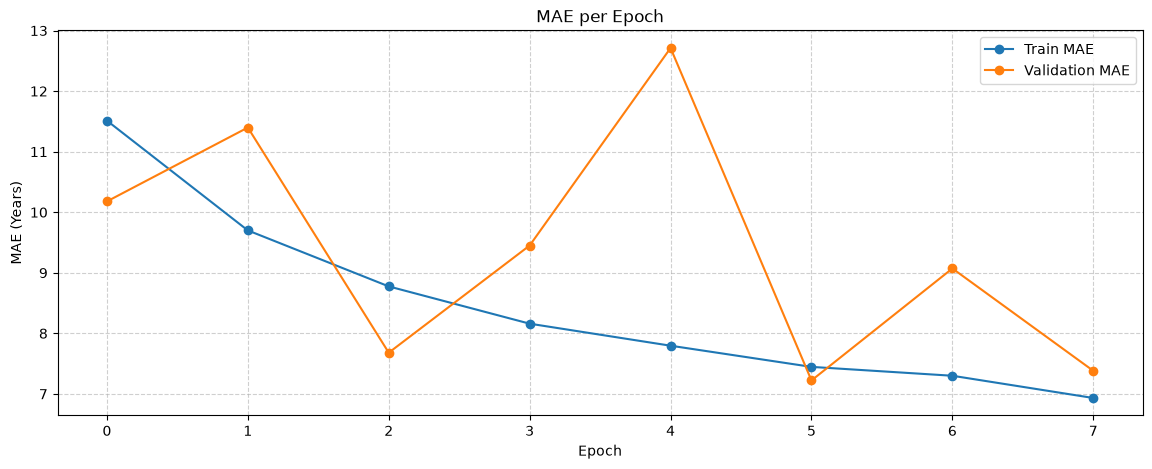

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(history.history["mae"], label="Train MAE", marker="o")
plt.plot(history.history["val_mae"], label="Validation MAE", marker="o")

plt.title("MAE per Epoch")
plt.xlabel("Epoch")
plt.ylabel("MAE (Years)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

75/75 ━━━━━━━━━━━━━━━━━━━━ 6s 76ms/step


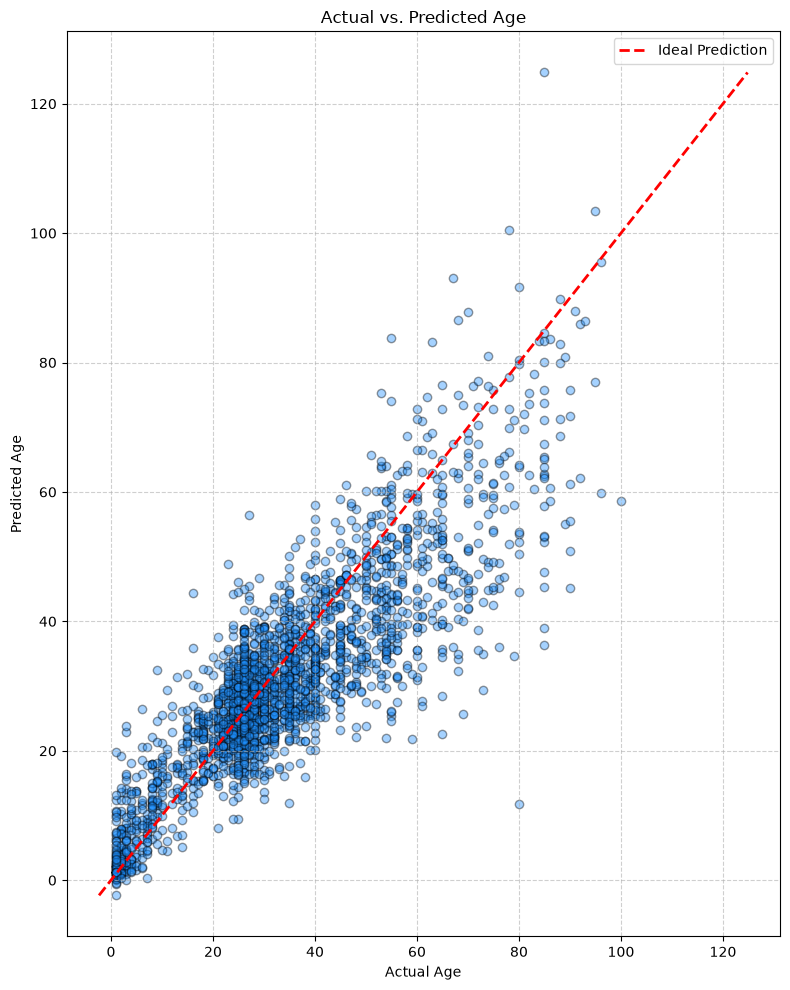

In [26]:
y_pred = model.predict(val_ds).flatten()
y_actual = np.concatenate([ages.numpy() for _, ages in val_ds])

plt.figure(figsize=(8, 10))
plt.scatter(y_actual, y_pred, alpha=0.4, color="dodgerblue", edgecolors="k")
limits = [
    min(y_actual.min(), y_pred.min()),
    max(y_actual.max(), y_pred.max())
]
plt.plot(limits, limits, "r--", linewidth=2, label="Ideal Prediction")
plt.title("Actual vs. Predicted Age")
plt.xlabel("Actual Age")
plt.ylabel("Predicted Age")
plt.legend()
plt.grid(alpha=0.6, linestyle="--")
plt.tight_layout()

plt.savefig("actual_vs_predicted_scatter.png")
plt.show()